# 04 · Models and evaluation
**Owner:** Kasula Lalithendra

1. **train**: tune Logistic Regression, Random Forest and Gradient Boosting with GroupKFold (by premise)
2. **validation**: pick the best model
3. **test**: evaluate once (precision, recall, F1, confusion matrix, confidence interval, error analysis)

In [1]:
# ─── IMPORTS ─────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

In [2]:
# ─── LOAD DATA ─────
data = pd.read_csv("../data/processed/features.csv")

FEATURES = ["num_variables", "n_correlations", "n_independencies",
            "rel_collider", "rel_confounder", "rel_direct_cause", "rel_indirect_cause",
            "xy_correlated", "xy_independent", "xy_independent_given",
            "edge_x_to_y", "edge_y_to_x", "edge_undirected", "log_mec_size", "mec_support"]

train = data[data["split"] == "train"]
validation = data[data["split"] == "validation"]
test = data[data["split"] == "test"]

y_train = train["label"]
y_val = validation["label"]
y_test = test["label"]

print(train.shape, validation.shape, test.shape)

(35340, 24) (1026, 24) (1162, 24)


In [3]:
# ─── STEP 1: BUILD THE FEATURES (TF-IDF + STRUCTURED) ─────
# everything is fitted on train only, then applied to validation and test
tfidf_premise = TfidfVectorizer(token_pattern=r"\b\w+\b", ngram_range=(1, 2), min_df=2, sublinear_tf=True)
tfidf_hypothesis = TfidfVectorizer(token_pattern=r"\b\w+\b", ngram_range=(1, 2), min_df=2, sublinear_tf=True)
scaler = StandardScaler()

X_train = np.hstack([tfidf_premise.fit_transform(train["premise"]).toarray(),
                     tfidf_hypothesis.fit_transform(train["hypothesis"]).toarray(),
                     scaler.fit_transform(train[FEATURES])])
X_val = np.hstack([tfidf_premise.transform(validation["premise"]).toarray(),
                   tfidf_hypothesis.transform(validation["hypothesis"]).toarray(),
                   scaler.transform(validation[FEATURES])])
X_test = np.hstack([tfidf_premise.transform(test["premise"]).toarray(),
                    tfidf_hypothesis.transform(test["hypothesis"]).toarray(),
                    scaler.transform(test[FEATURES])])

print(X_train.shape, X_val.shape, X_test.shape)

(35340, 256) (1026, 256) (1162, 256)


In [4]:
# ─── STEP 2: LOGISTIC REGRESSION ─────
# GroupKFold keeps all rows of a premise in the same fold
# class_weight="balanced" makes the rare valid class count as much as the invalid one
lr_search = GridSearchCV(LogisticRegression(max_iter=3000, class_weight="balanced"),
                         {"C": [0.1, 1, 10]}, cv=GroupKFold(5), scoring="f1", n_jobs=-1)
lr_search.fit(X_train, y_train, groups=train["premise_id"])
print(lr_search.best_params_, round(lr_search.best_score_, 3))

{'C': 10} 0.819


In [5]:
# ─── STEP 3: RANDOM FOREST ─────
rf_search = GridSearchCV(RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
                         {"max_depth": [None, 20], "min_samples_leaf": [1, 5]}, cv=GroupKFold(5), scoring="f1", n_jobs=-1)
rf_search.fit(X_train, y_train, groups=train["premise_id"])
print(rf_search.best_params_, round(rf_search.best_score_, 3))

{'max_depth': None, 'min_samples_leaf': 1} 0.905


In [6]:
# ─── STEP 4: GRADIENT BOOSTING ─────
gb_search = GridSearchCV(HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
                         {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [15, 31]}, cv=GroupKFold(5), scoring="f1", n_jobs=-1)
gb_search.fit(X_train, y_train, groups=train["premise_id"])
print(gb_search.best_params_, round(gb_search.best_score_, 3))

{'learning_rate': 0.1, 'max_leaf_nodes': 31} 0.915


In [7]:
# ─── STEP 5: PICK THE MODEL ON VALIDATION ─────
lr_val_pred = lr_search.predict(X_val)
rf_val_pred = rf_search.predict(X_val)
gb_val_pred = gb_search.predict(X_val)

val_results = pd.DataFrame({
    "precision": [precision_score(y_val, lr_val_pred), precision_score(y_val, rf_val_pred), precision_score(y_val, gb_val_pred)],
    "recall": [recall_score(y_val, lr_val_pred), recall_score(y_val, rf_val_pred), recall_score(y_val, gb_val_pred)],
    "F1": [f1_score(y_val, lr_val_pred), f1_score(y_val, rf_val_pred), f1_score(y_val, gb_val_pred)],
}, index=["Logistic Regression", "Random Forest", "Gradient Boosting"])
val_results.round(3)

,precision,recall,F1
Logistic Regression,0.704,0.884,0.784
Random Forest,0.770,0.961,0.855
Gradient Boosting,0.833,0.853,0.843


In [8]:
# the model with the best validation F1 is our final model
models = {"Logistic Regression": lr_search, "Random Forest": rf_search, "Gradient Boosting": gb_search}
best_name = val_results["F1"].idxmax()
best_model = models[best_name]
best_name

'Random Forest'

In [9]:
# ─── STEP 6: FINAL RESULTS ON TEST ─────
lr_test_pred = lr_search.predict(X_test)
rf_test_pred = rf_search.predict(X_test)
gb_test_pred = gb_search.predict(X_test)
rule_pred = (test["mec_support"] == 1).astype(int)   # no learning: valid if PC says it must be true

test_results = pd.DataFrame({
    "precision": [precision_score(y_test, lr_test_pred), precision_score(y_test, rf_test_pred),
                  precision_score(y_test, gb_test_pred), precision_score(y_test, rule_pred)],
    "recall": [recall_score(y_test, lr_test_pred), recall_score(y_test, rf_test_pred),
               recall_score(y_test, gb_test_pred), recall_score(y_test, rule_pred)],
    "F1": [f1_score(y_test, lr_test_pred), f1_score(y_test, rf_test_pred),
           f1_score(y_test, gb_test_pred), f1_score(y_test, rule_pred)],
}, index=["Logistic Regression", "Random Forest", "Gradient Boosting", "Symbolic rule (no learning)"])
test_results.round(3)

,precision,recall,F1
Logistic Regression,0.783,0.922,0.847
Random Forest,0.860,0.956,0.905
Gradient Boosting,0.907,0.972,0.938
Symbolic rule (no learning),0.920,0.828,0.871


The model was chosen on validation, so we keep it even if another one scores higher on test.

In [10]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

In [11]:
# ─── STEP 7: CONFUSION MATRIX ─────
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

In [12]:
# True Negatives:
tn

np.int64(954)

In [13]:
# False Positives:
fp

np.int64(28)

In [14]:
# False Negatives:
fn

np.int64(8)

In [15]:
# True Positives:
tp

np.int64(172)

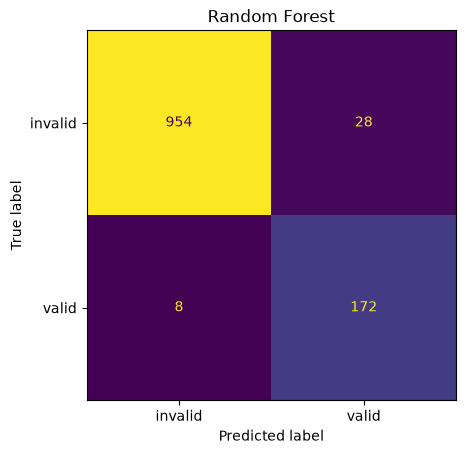

In [16]:
ConfusionMatrixDisplay(cm, display_labels=["invalid", "valid"]).plot(colorbar=False)
plt.title(best_name)
plt.show()

In [17]:
# ─── STEP 8: 95% CONFIDENCE INTERVAL (BOOTSTRAP) ─────
# rows from the same premise are not independent, so we resample whole premises 1000 times
results = test[["premise_id", "template", "num_variables", "hypothesis", "label"]].copy()
results["pred"] = y_pred
results["proba"] = y_proba

rng = np.random.default_rng(42)
premises = results["premise_id"].unique()
f1_scores = []
for i in range(1000):
    chosen = rng.choice(premises, size=len(premises))
    sample = pd.DataFrame({"premise_id": chosen}).merge(results, on="premise_id")
    f1_scores.append(f1_score(sample["label"], sample["pred"]))

print("test F1:", round(f1_score(y_test, y_pred), 3))
print("95% CI: ", np.percentile(f1_scores, [2.5, 97.5]).round(3))

test F1: 0.905
95% CI:  [0.852 0.937]


In [18]:
# ─── STEP 9: ERROR ANALYSIS ─────
results["wrong"] = results["pred"] != results["label"]
results["false_alarm"] = (results["pred"] == 1) & (results["label"] == 0)
results["miss"] = (results["pred"] == 0) & (results["label"] == 1)

# errors by hypothesis type
results.groupby("template")[["wrong", "false_alarm", "miss"]].sum()

,wrong,false_alarm,miss
template,,,
child,0,0,0
has_collider,15,14,1
has_confounder,3,0,3
non-child descendant,3,2,1
non-parent ancestor,7,4,3
parent,8,8,0


* "child" claims are never valid and the model makes no mistakes on them.
* Most mistakes are false alarms on "collider" and "parent" claims, the same types where PC and the dataset
  labels disagree in notebook 02.

In [19]:
# errors by number of variables (train only had 5-6)
results.groupby("num_variables")["wrong"].agg(["count", "sum", "mean"])

,count,sum,mean
num_variables,,,
2,6,0,0.000000
3,48,3,0.062500
4,72,2,0.027778
5,514,16,0.031128
6,522,15,0.028736


The small graphs (2–4 variables) have about the same error rate as the big ones even though train never had them,
because the structured features come from the parser and PC, not from memorising sentences.

In [20]:
# the most confident mistakes
results[results["wrong"]].sort_values("proba", ascending=False).head()

,premise_id,template,num_variables,hypothesis,label,pred,proba,wrong,false_alarm,miss
37422,2375,parent,6,B directly causes E.,0,1,0.990000,True,True,False
37071,2371,parent,6,B directly causes F.,0,1,0.953333,True,True,False
37176,2356,parent,6,B directly causes D.,0,1,0.853333,True,True,False
37160,2356,parent,6,A directly causes D.,0,1,0.830000,True,True,False
37145,2356,parent,6,C directly causes D.,0,1,0.826667,True,True,False


In [21]:
# ─── STEP 10: SAVE TEST PREDICTIONS FOR NOTEBOOK 05 ─────
test[["premise_id", "hypothesis", "template", "relation", "x", "y", "label"]].assign(proba=y_proba, pred=y_pred).to_csv(
    "../data/processed/test_predictions.csv", index=False)